In [18]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np


# 1.1
В государстве 100 городов, и из каждого из них выходит 4 дороги. Сколько всего дорог в государстве?

In [ ]:
def calculate_roads(num_cities: int, degree_per_city: int) -> int:
    sum_degrees = num_cities * degree_per_city
    total_roads = sum_degrees // 2
    return total_roads

cities = 100
degree = 4

total_roads = calculate_roads(cities, degree)
print(f"Порядок графа |V|: {cities}")
print(f"Степень каждой вершины deg(v): {degree}")
print(f"Сумма степеней sum(deg(v)): {cities * degree}")
print(f"Количество дорог |E| = {cities * degree} / 2 = {total_roads}")

Порядок графа |V|: 100
Степень каждой вершины deg(v): 4
Сумма степеней sum(deg(v)): 400
Количество дорог |E| = 400 / 2 = 200


# 1.2

Может ли в государстве, в котором из каждого города выходит 3 дороги, быть ровно 100 дорог?

In [25]:
def check_graph_existence(total_roads: int, degree_per_city: int) -> dict:
    sum_degrees = 2 * total_roads
    is_integer = (sum_degrees % degree_per_city == 0)
    num_cities = sum_degrees / degree_per_city

    return {
        "2 * |E|": sum_degrees, #найдем суммарную степень для всего графа
        "deg(v)": degree_per_city, #по условию какая степень города
        "|V|": num_cities, #можем вычислить количество городов, зная суммарную степень и степень каждого города отдельно
        "is_integer": is_integer, 
        "possible": is_integer #если не целое, то не может
    }

result = check_graph_existence(total_roads=100, degree_per_city=3)
print(f"2 * |E| = {result['2 * |E|']}")
print(f"Степень deg(v) = {result['deg(v)']}")
print(f"Городов |V| = {result['2 * |E|']} / {result['deg(v)']} = {result['|V|']:.4f}")
print(f"Вывод: такое государство существовать {'может' if result['possible'] else 'не может'}.")

2 * |E| = 200
Степень deg(v) = 3
Городов |V| = 200 / 3 = 66.6667
Вывод: такое государство существовать не может.


# 1.3
Определить порядок и размер следующего графа. Определить степени всех вершин.

In [31]:
def deg_size(G):
    #Определить порядок и размер
    order = G.number_of_nodes()
    print(f"Порядок графа 1 (|V|): {order}")
    
    size = G.number_of_edges()
    print(f"Размер графа 1 (|E|): {size}")
    
    #определить степени всех вершин
    degrees = dict(G.degree())
    print("Степени вершин:")
    for node in sorted(degrees.keys()):
        print(f"  deg({node}) = {degrees[node]}")
    print(f"Сумма степеней: {sum(degrees.values())} (должна быть 2 * {size} = {2 * size})")


Порядок графа 1 (|V|): 4
Размер графа 1 (|E|): 7
Степени вершин:
  deg(a) = 4
  deg(b) = 3
  deg(c) = 4
  deg(d) = 3
Сумма степеней: 14 (должна быть 2 * 7 = 14)


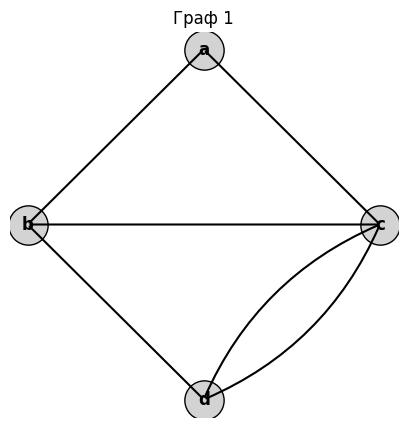

In [33]:
G1 = nx.MultiGraph()
vertices_1 = ['a', 'b', 'c', 'd']
G1.add_nodes_from(vertices_1)
edges_1 = [
    ('a', 'b', {'id': 1}),
    ('b', 'c', {'id': 2}),
    ('b', 'd', {'id': 3}),
    ('a', 'c', {'id': 4}),
    ('c', 'd', {'id': 5}),
    ('c', 'd', {'id': 6}),
    ('a', 'a', {'id': 7}),  #петля
]
for u, v, data in edges_1:
    G1.add_edge(u, v, **data)

deg_size(G1)

#viz
pos_1 = {'a': (0, 1), 'b': (-1, 0), 'c': (1, 0), 'd': (0, -1)}
fig, ax = plt.subplots(figsize=(5, 5))
nx.draw_networkx_nodes(G1, pos_1, ax=ax, node_color='lightgray', edgecolors='black', node_size=800)
nx.draw_networkx_labels(G1, pos_1, ax=ax, font_size=12, font_weight='bold')

#ребра без перекрытия
for u, v, k, d in G1.edges(keys=True, data=True):
    rad = 0.2 if k == 1 else (-0.2 if k == 0 and u != v and G1.number_of_edges(u, v) > 1 else 0.0)
    connectionstyle = f"arc3,rad={rad}" if u != v else "arc3,rad=0.5"
    ax.annotate("", xy=pos_1[v], xytext=pos_1[u],
                arrowprops=dict(arrowstyle="-", connectionstyle=connectionstyle, lw=1.5))

ax.set_title("Граф 1")
ax.axis('off')
plt.show()

Порядок графа 1 (|V|): 7
Размер графа 1 (|E|): 4
Степени вершин:
  deg(A) = 1
  deg(B) = 2
  deg(C) = 2
  deg(D) = 1
  deg(E) = 0
  deg(F) = 1
  deg(G) = 1
Сумма степеней: 8 (должна быть 2 * 4 = 8)


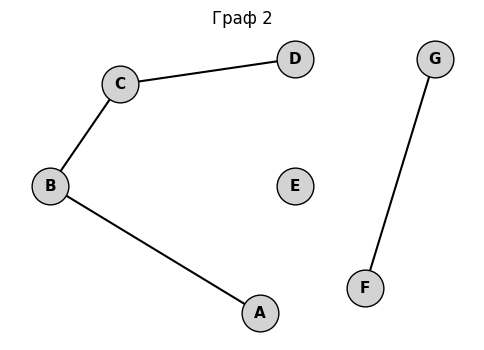

In [34]:
G2 = nx.Graph()
vertices_2 = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
G2.add_nodes_from(vertices_2)
edges_2 = [
    ('A', 'B'),
    ('B', 'C'),
    ('C', 'D'),
    ('F', 'G')
]
G2.add_edges_from(edges_2)

deg_size(G2)


# Визуализация
pos_2 = {
    'A': (0.8, 0.0),
    'B': (0.2, 0.5),
    'C': (0.4, 0.9),
    'D': (0.9, 1.0),
    'E': (0.9, 0.5),
    'F': (1.1, 0.1),
    'G': (1.3, 1.0)
}

fig, ax = plt.subplots(figsize=(6, 4))
nx.draw_networkx_nodes(G2, pos_2, ax=ax, node_color='lightgray', edgecolors='black', node_size=700)
nx.draw_networkx_edges(G2, pos_2, ax=ax, width=1.5)
nx.draw_networkx_labels(G2, pos_2, ax=ax, font_size=11, font_weight='bold')

ax.set_title("Граф 2")
ax.axis('off')
plt.show()

Порядок графа 1 (|V|): 5
Размер графа 1 (|E|): 9
Степени вершин:
  deg(2) = 4
  deg(3) = 3
  deg(4) = 4
  deg(5) = 2
  deg(6) = 5
Сумма степеней: 18 (должна быть 2 * 9 = 18)


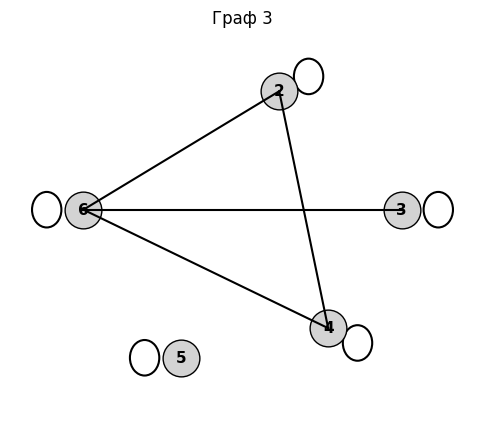

In [38]:
G3 = nx.MultiGraph()

vertices_3 = [2, 3, 4, 5, 6]
G3.add_nodes_from(vertices_3)
simple_edges = [
    (6, 2),
    (6, 3),
    (6, 4),
    (2, 4)
]
G3.add_edges_from(simple_edges)
loops = [(v, v) for v in vertices_3]
G3.add_edges_from(loops)

deg_size(G3)

#viz
pos_3 = {
    6: (0.0, 0.5),
    2: (0.8, 0.9),
    3: (1.3, 0.5),
    4: (1.0, 0.1),
    5: (0.4, 0.0)
}

fig, ax = plt.subplots(figsize=(6, 5))
nx.draw_networkx_nodes(G3, pos_3, ax=ax, node_color='lightgray', edgecolors='black', node_size=700)
nx.draw_networkx_labels(G3, pos_3, ax=ax, font_size=11, font_weight='bold')

#прямые ребер
for u, v in simple_edges:
    ax.plot([pos_3[u][0], pos_3[v][0]], [pos_3[u][1], pos_3[v][1]], color='black', lw=1.5)

#отрисовка петель
loop_offsets = {6: (-0.15, 0), 2: (0.12, 0.05), 3: (0.15, 0), 4: (0.12, -0.05), 5: (-0.15, 0)}
for v, (dx, dy) in loop_offsets.items():
    circle = plt.Circle((pos_3[v][0] + dx, pos_3[v][1] + dy), 0.06, color='black', fill=False, lw=1.5)
    ax.add_patch(circle)

ax.set_xlim(-0.3, 1.6)
ax.set_ylim(-0.2, 1.1)
ax.set_title("Граф 3")
ax.axis('off')
plt.show()

Порядок графа 4 (|V|): 8
Размер графа 4 (|E|): 17

Степени вершин орграфа:
Вершина deg-(вход)    deg+(исход)   deg(полная)   
--------------------------------------------------
a       0             5             5             
b       1             2             3             
c       4             0             4             
d       1             2             3             
e       3             1             4             
f       4             3             7             
g       2             2             4             
h       2             2             4             
--------------------------------------------------
Сумма:  17            17            34            
Проверка: sum(deg-) = sum(deg+) = 17; sum(deg) = 2 * 17 = 34


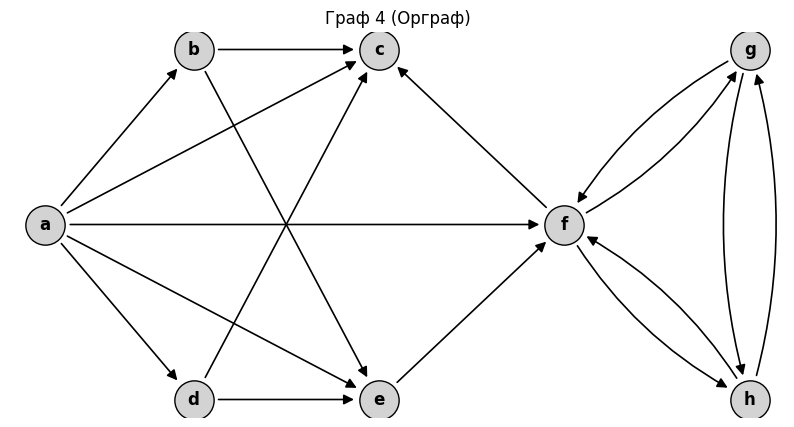

In [8]:
# Инициализация ориентированного мультиграфа
D = nx.MultiDiGraph()

# Добавление вершин
nodes_4 = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h']
D.add_nodes_from(nodes_4)

# Добавление дуг
directed_edges = [
    # Из a
    ('a', 'b'), ('a', 'c'), ('a', 'd'), ('a', 'e'), ('a', 'f'),
    # Из b
    ('b', 'c'), ('b', 'e'),
    # Из d
    ('d', 'c'), ('d', 'e'),
    # Из e
    ('e', 'f'),
    # Из f
    ('f', 'c'), ('f', 'g'), ('f', 'h'),
    # Из g
    ('g', 'f'), ('g', 'h'),
    # Из h
    ('h', 'f'), ('h', 'g')
]

D.add_edges_from(directed_edges)

order_4 = D.number_of_nodes()
size_4 = D.number_of_edges()

in_degrees = dict(D.in_degree())
out_degrees = dict(D.out_degree())
total_degrees = {v: in_degrees[v] + out_degrees[v] for v in nodes_4}

print(f"Порядок графа 4 (|V|): {order_4}")
print(f"Размер графа 4 (|E|): {size_4}")
print("\nСтепени вершин орграфа:")
print(f"{'Вершина':<8}{'deg-(вход)':<14}{'deg+(исход)':<14}{'deg(полная)':<14}")
print("-" * 50)
for node in nodes_4:
    print(f"{node:<8}{in_degrees[node]:<14}{out_degrees[node]:<14}{total_degrees[node]:<14}")

print("-" * 50)
print(f"{'Сумма:':<8}{sum(in_degrees.values()):<14}{sum(out_degrees.values()):<14}{sum(total_degrees.values()):<14}")
print(f"Проверка: sum(deg-) = sum(deg+) = {size_4}; sum(deg) = 2 * {size_4} = {2 * size_4}")

# Визуализация
pos_4 = {
    'a': (0.0, 0.5),
    'b': (0.4, 0.9),
    'd': (0.4, 0.1),
    'c': (0.9, 0.9),
    'e': (0.9, 0.1),
    'f': (1.4, 0.5),
    'g': (1.9, 0.9),
    'h': (1.9, 0.1)
}

fig, ax = plt.subplots(figsize=(10, 5))
nx.draw_networkx_nodes(D, pos_4, ax=ax, node_color='lightgray', edgecolors='black', node_size=800)
nx.draw_networkx_labels(D, pos_4, ax=ax, font_size=12, font_weight='bold')

# Отрисовка дуг с искривлением для антипараллельных пар
for u, v in directed_edges:
    rad = 0.15 if (v, u) in directed_edges else 0.0
    ax.annotate("", xy=pos_4[v], xytext=pos_4[u],
                arrowprops=dict(arrowstyle="-|>", color="black",
                                connectionstyle=f"arc3,rad={rad}", lw=1.2,
                                shrinkA=18, shrinkB=18, mutation_scale=15))

ax.set_title("Граф 4 (Орграф)")
ax.axis('off')
plt.show()

# 1.4

# 1.5


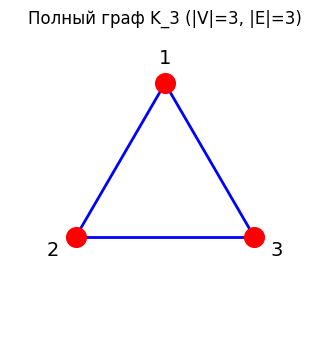

Число вершин: 3
Число рёбер: 3
Максимальное число рёбер для планарного графа: 3
Является ли граф планарным: True


In [10]:
#a
V_count = 3
E_count = V_count * (V_count - 1) // 2
max_planar_E = 3 * V_count - 6 if V_count >= 3 else E_count

angles = np.linspace(np.pi / 2, np.pi / 2 + 2 * np.pi, V_count, endpoint=False)
x = np.cos(angles)
y = np.sin(angles)
vertices = list(range(1, V_count + 1))

fig, ax = plt.subplots(figsize=(4, 4))
for i in range(V_count):
    for j in range(i + 1, V_count):
        ax.plot([x[i], x[j]], [y[i], y[j]], 'b-', lw=2)

ax.scatter(x, y, color='red', s=200, zorder=5)
for i in range(V_count):
    ax.text(x[i] * 1.25, y[i] * 1.25, str(vertices[i]), fontsize=14, ha='center', va='center')

ax.set_title(f"Полный граф K_3 (|V|={V_count}, |E|={E_count})")
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.axis('off')
plt.show()

# Проверка планарности
is_planar = E_count <= max_planar_E
print(f"Число вершин: {V_count}")
print(f"Число рёбер: {E_count}")
print(f"Максимальное число рёбер для планарного графа: {max_planar_E}")
print(f"Является ли граф планарным: {is_planar}")

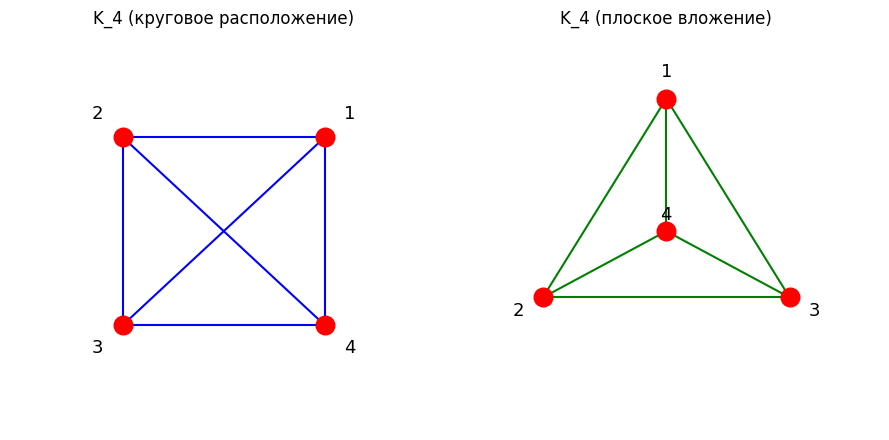

Число вершин: 4
Число рёбер: 6
Максимальное число рёбер для планарного графа: 6
Является ли граф планарным: True


In [11]:
# б
V_count = 4
E_count = V_count * (V_count - 1) // 2
max_planar_E = 3 * V_count - 6

angles = np.linspace(np.pi / 4, np.pi / 4 + 2 * np.pi, V_count, endpoint=False)
x_circ = np.cos(angles)
y_circ = np.sin(angles)
pos_planar = {
    1: np.array([0.0, 1.0]),
    2: np.array([-np.sqrt(3)/2, -0.5]),
    3: np.array([np.sqrt(3)/2, -0.5]),
    4: np.array([0.0, 0.0])
}

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

# 1. Круговая укладка
axes[0].set_title("K_4 (круговое расположение)")
for i in range(V_count):
    for j in range(i + 1, V_count):
        axes[0].plot([x_circ[i], x_circ[j]], [y_circ[i], y_circ[j]], 'b-', lw=1.5)
axes[0].scatter(x_circ, y_circ, color='red', s=180, zorder=5)
for i in range(V_count):
    axes[0].text(x_circ[i] * 1.25, y_circ[i] * 1.25, str(i + 1), fontsize=13, ha='center', va='center')
axes[0].set_xlim(-1.5, 1.5)
axes[0].set_ylim(-1.5, 1.5)
axes[0].axis('off')

# 2. Плоская укладка без пересечений
axes[1].set_title("K_4 (плоское вложение)")
for i in range(1, 5):
    for j in range(i + 1, 5):
        axes[1].plot([pos_planar[i][0], pos_planar[j][0]],
                     [pos_planar[i][1], pos_planar[j][1]], 'g-', lw=1.5)
for i in range(1, 5):
    axes[1].scatter(pos_planar[i][0], pos_planar[i][1], color='red', s=180, zorder=5)
    axes[1].text(pos_planar[i][0] + (0.0 if i == 4 else pos_planar[i][0]*0.2),
                 pos_planar[i][1] + (0.12 if i == 4 else pos_planar[i][1]*0.2),
                 str(i), fontsize=13, ha='center', va='center')
axes[1].set_xlim(-1.5, 1.5)
axes[1].set_ylim(-1.5, 1.5)
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Проверка критерия
is_planar = E_count <= max_planar_E
print(f"Число вершин: {V_count}")
print(f"Число рёбер: {E_count}")
print(f"Максимальное число рёбер для планарного графа: {max_planar_E}")
print(f"Является ли граф планарным: {is_planar}")

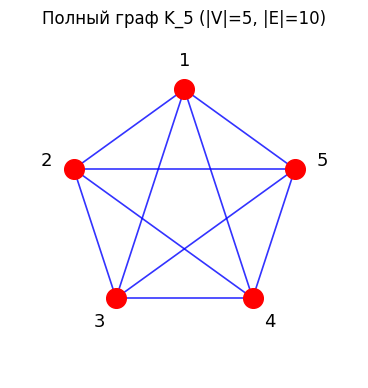

Число вершин: 5
Число рёбер: 10
Максимальное число рёбер для планарного графа: 9
Критерий E <= 3V - 6: 10 <= 9 -> False
Является ли граф планарным: False


In [12]:
#в
V_count = 5
E_count = V_count * (V_count - 1) // 2
max_planar_E = 3 * V_count - 6

angles = np.linspace(np.pi / 2, np.pi / 2 + 2 * np.pi, V_count, endpoint=False)
x = np.cos(angles)
y = np.sin(angles)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
for i in range(V_count):
    for j in range(i + 1, V_count):
        ax.plot([x[i], x[j]], [y[i], y[j]], 'b-', lw=1.2, alpha=0.8)

ax.scatter(x, y, color='red', s=200, zorder=5)
for i in range(V_count):
    ax.text(x[i] * 1.25, y[i] * 1.25, str(i + 1), fontsize=13, ha='center', va='center')

ax.set_title(f"Полный граф K_5 (|V|={V_count}, |E|={E_count})")
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.axis('off')
plt.show()

# Проверка критерия планарности
is_planar = E_count <= max_planar_E
print(f"Число вершин: {V_count}")
print(f"Число рёбер: {E_count}")
print(f"Максимальное число рёбер для планарного графа: {max_planar_E}")
print(f"Критерий E <= 3V - 6: {E_count} <= {max_planar_E} -> {is_planar}")
print(f"Является ли граф планарным: {is_planar}")

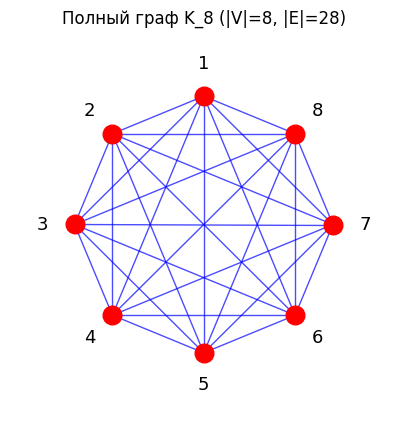

Число вершин: 8
Число рёбер: 28
Максимальное число рёбер для планарного графа: 18
Критерий E <= 3V - 6: 28 <= 18 -> False
Является ли граф планарным: False


In [13]:
#г
V_count = 8
E_count = V_count * (V_count - 1) // 2
max_planar_E = 3 * V_count - 6

angles = np.linspace(np.pi / 2, np.pi / 2 + 2 * np.pi, V_count, endpoint=False)
x = np.cos(angles)
y = np.sin(angles)

fig, ax = plt.subplots(figsize=(5, 5))
for i in range(V_count):
    for j in range(i + 1, V_count):
        ax.plot([x[i], x[j]], [y[i], y[j]], 'b-', lw=1.0, alpha=0.7)

ax.scatter(x, y, color='red', s=180, zorder=5)
for i in range(V_count):
    ax.text(x[i] * 1.25, y[i] * 1.25, str(i + 1), fontsize=13, ha='center', va='center')

ax.set_title(f"Полный граф K_8 (|V|={V_count}, |E|={E_count})")
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.axis('off')
plt.show()

# Проверка критерия планарности
is_planar = E_count <= max_planar_E
print(f"Число вершин: {V_count}")
print(f"Число рёбер: {E_count}")
print(f"Максимальное число рёбер для планарного графа: {max_planar_E}")
print(f"Критерий E <= 3V - 6: {E_count} <= {max_planar_E} -> {is_planar}")
print(f"Является ли граф планарным: {is_planar}")

# 1.6
Определить число возможных простых путей между вершинами a и c


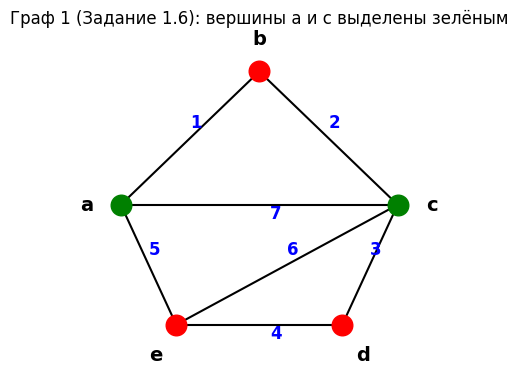

Всего простых путей между a и c: 4

Путь 1 (длина 2 ребра): a -> b -> c | Рёбра: [1, 2]
Путь 2 (длина 1 ребра): a -> c | Рёбра: [7]
Путь 3 (длина 2 ребра): a -> e -> c | Рёбра: [5, 6]
Путь 4 (длина 3 ребра): a -> e -> d -> c | Рёбра: [5, 4, 3]


In [14]:
#Граф 1: пути между a и c
# Координаты вершин графа 1 согласно исходному чертежу
pos1 = {
    'a': (-1.0, 0.0),
    'b': (0.0, 1.0),
    'c': (1.0, 0.0),
    'd': (0.6, -0.9),
    'e': (-0.6, -0.9)
}

# Ребра с номерами из чертежа
edges_with_labels = [
    ('a', 'b', '1'),
    ('b', 'c', '2'),
    ('c', 'd', '3'),
    ('e', 'd', '4'),
    ('a', 'e', '5'),
    ('e', 'c', '6'),
    ('a', 'c', '7')
]

# 1. Визуализация графа
fig, ax = plt.subplots(figsize=(5, 4.5))
for u, v, lbl in edges_with_labels:
    x1, y1 = pos1[u]
    x2, y2 = pos1[v]
    ax.plot([x1, x2], [y1, y2], 'k-', lw=1.5)
    # Смещение подписи ребра
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    offset_x = 0.08 if (u, v) in [('a', 'c'), ('e', 'd')] else 0.0
    offset_y = 0.08 if (u, v) not in [('a', 'c'), ('e', 'd')] else -0.1
    ax.text(mx + offset_x, my + offset_y, lbl, color='blue', fontsize=12, fontweight='bold')

for node, (x_coord, y_coord) in pos1.items():
    color = 'green' if node in ['a', 'c'] else 'red'
    ax.scatter(x_coord, y_coord, s=220, color=color, zorder=5)
    ax.text(x_coord * 1.25, y_coord * 1.25, node, fontsize=14, fontweight='bold', ha='center', va='center')

ax.set_title("Граф 1 (Задание 1.6): вершины a и c выделены зелёным")
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.3, 1.3)
ax.axis('off')
plt.show()

# 2. Поиск всех простых путей от 'a' до 'c'
adj1 = {
    'a': ['b', 'c', 'e'],
    'b': ['a', 'c'],
    'c': ['a', 'b', 'd', 'e'],
    'd': ['c', 'e'],
    'e': ['a', 'c', 'd']
}

def find_simple_paths(adj, current, target, visited=None):
    if visited is None:
        visited = []
    visited = visited + [current]
    if current == target:
        return [visited]
    paths = []
    for neighbor in sorted(adj.get(current, [])):
        if neighbor not in visited:
            paths.extend(find_simple_paths(adj, neighbor, target, visited))
    return paths

paths1 = find_simple_paths(adj1, 'a', 'c')

# Сопоставление ребер с их номерами
edge_to_num = {}
for u, v, lbl in edges_with_labels:
    edge_to_num[(u, v)] = lbl
    edge_to_num[(v, u)] = lbl

print(f"Всего простых путей между a и c: {len(paths1)}\n")
for idx, path in enumerate(paths1, 1):
    path_str = " -> ".join(path)
    edges_seq = [edge_to_num[(path[i], path[i+1])] for i in range(len(path) - 1)]
    edges_str = ", ".join(edges_seq)
    print(f"Путь {idx} (длина {len(path) - 1} ребра): {path_str} | Рёбра: [{edges_str}]")

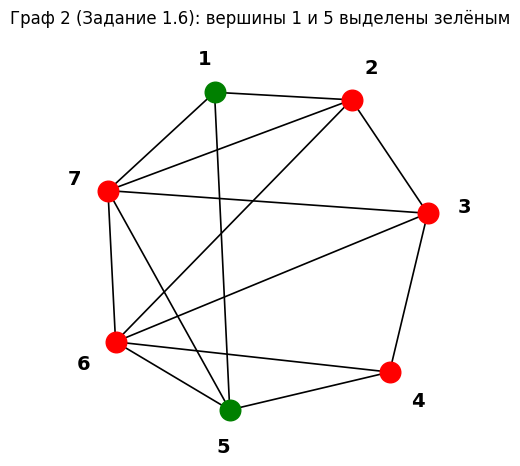

Всего простых путей между 1 и 5: 43

--- Длина 1 (1 путей) ---
   1. 1 -> 5
--- Длина 2 (1 путей) ---
   1. 1 -> 7 -> 5
--- Длина 3 (3 путей) ---
   1. 1 -> 2 -> 6 -> 5
   2. 1 -> 2 -> 7 -> 5
   3. 1 -> 7 -> 6 -> 5
--- Длина 4 (10 путей) ---
   1. 1 -> 2 -> 3 -> 4 -> 5
   2. 1 -> 2 -> 3 -> 6 -> 5
   3. 1 -> 2 -> 3 -> 7 -> 5
   4. 1 -> 2 -> 6 -> 4 -> 5
   5. 1 -> 2 -> 6 -> 7 -> 5
   6. 1 -> 2 -> 7 -> 6 -> 5
   7. 1 -> 7 -> 2 -> 6 -> 5
   8. 1 -> 7 -> 3 -> 4 -> 5
   9. 1 -> 7 -> 3 -> 6 -> 5
  10. 1 -> 7 -> 6 -> 4 -> 5
--- Длина 5 (16 путей) ---
   1. 1 -> 2 -> 3 -> 4 -> 6 -> 5
   2. 1 -> 2 -> 3 -> 6 -> 4 -> 5
   3. 1 -> 2 -> 3 -> 6 -> 7 -> 5
   4. 1 -> 2 -> 3 -> 7 -> 6 -> 5
   5. 1 -> 2 -> 6 -> 3 -> 4 -> 5
   6. 1 -> 2 -> 6 -> 3 -> 7 -> 5
   7. 1 -> 2 -> 7 -> 3 -> 4 -> 5
   8. 1 -> 2 -> 7 -> 3 -> 6 -> 5
   9. 1 -> 2 -> 7 -> 6 -> 4 -> 5
  10. 1 -> 7 -> 2 -> 3 -> 4 -> 5
  11. 1 -> 7 -> 2 -> 3 -> 6 -> 5
  12. 1 -> 7 -> 2 -> 6 -> 4 -> 5
  13. 1 -> 7 -> 3 -> 2 -> 6 -> 5
  14. 1 -> 7 -> 3 -> 4

In [16]:
#Граф 2: пути между 1 и 5

# Координаты вершин семиугольника в соответствии с чертежом
pos2 = {
    1: (-0.3, 1.0),
    2: (0.6, 0.95),
    3: (1.1, 0.2),
    4: (0.85, -0.85),
    5: (-0.2, -1.1),
    6: (-0.95, -0.65),
    7: (-1.0, 0.35)
}

# 14 рёбер графа 2
edges2 = [
    (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 1),
    (1, 5), (2, 6), (2, 7), (3, 6), (3, 7), (4, 6), (5, 7)
]

# 1. Визуализация графа
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for u, v in edges2:
    x1, y1 = pos2[u]
    x2, y2 = pos2[v]
    ax.plot([x1, x2], [y1, y2], 'k-', lw=1.2)

for node, (x_coord, y_coord) in pos2.items():
    color = 'green' if node in [1, 5] else 'red'
    ax.scatter(x_coord, y_coord, s=220, color=color, zorder=5)
    ax.text(x_coord * 1.22, y_coord * 1.22, str(node), fontsize=14, fontweight='bold', ha='center', va='center')

ax.set_title("Граф 2 (Задание 1.6): вершины 1 и 5 выделены зелёным")
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.4, 1.4)
ax.axis('off')
plt.show()

# 2. Построение списков смежности
adj2 = {i: [] for i in range(1, 8)}
for u, v in edges2:
    adj2[u].append(v)
    adj2[v].append(u)

# 3. Поиск всех простых путей от 1 до 5
def find_simple_paths(adj, current, target, visited=None):
    if visited is None:
        visited = []
    visited = visited + [current]
    if current == target:
        return [visited]
    paths = []
    for neighbor in sorted(adj.get(current, [])):
        if neighbor not in visited:
            paths.extend(find_simple_paths(adj, neighbor, target, visited))
    return paths

paths2 = find_simple_paths(adj2, 1, 5)

# Классификация путей по длине (количеству рёбер)
by_length = {}
for p in paths2:
    l = len(p) - 1
    by_length.setdefault(l, []).append(p)

print(f"Всего простых путей между 1 и 5: {len(paths2)}\n")
for l in sorted(by_length.keys()):
    print(f"--- Длина {l} ({len(by_length[l])} путей) ---")
    for idx, p in enumerate(by_length[l], 1):
        print(f"  {idx:2d}. " + " -> ".join(map(str, p)))

# 1.7
Докажите, что на рёбрах связного графа можно так расставить стрелки, чтобы из некоторой вершины можно было добраться по стрелкам до любой другой.

1. Граф конечный и связный => $\exists$ остовное дерево в этом графе
2. Выбираем вершину на этом остовном дереве. Делаем её корнем. 
2.0. Мы можем сделать любую вершину корнем, потому что у дерева есть свойство, что между любыми двумя вершинами есть ровно один простой путь. 

--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.7 ---
Выбранная корневая вершина (r): 0
Рёбра остовного дерева T (ориентированы от r): {(0, 1), (1, 2), (0, 4), (0, 3), (4, 5)}
Остальные рёбра (произвольная ориентация): [(2, 3), (2, 5)]
Все вершины достижимы из вершины 0: True
  Путь из 0 в 0: 0
  Путь из 0 в 1: 0 -> 1
  Путь из 0 в 2: 0 -> 1 -> 2
  Путь из 0 в 3: 0 -> 3
  Путь из 0 в 4: 0 -> 4
  Путь из 0 в 5: 0 -> 4 -> 5


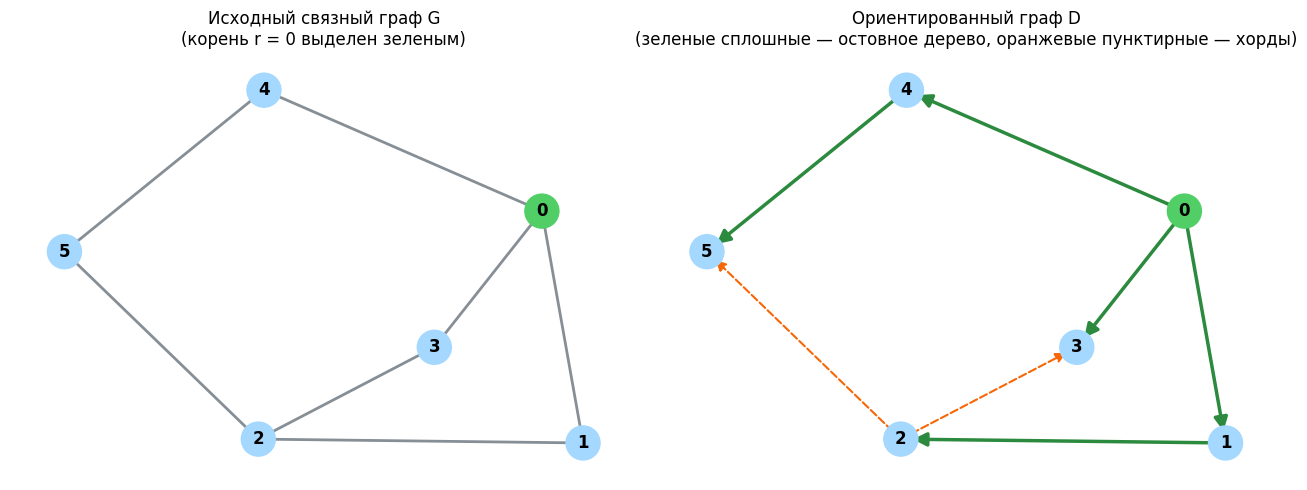

In [19]:
# Определения:
# 1. Граф G = (V, E) называется связным, если для любых двух вершин u, v существует путь между ними.
# 2. Остовное дерево T = (V, E_T) связного графа G — это ациклический связный подграф,
#    содержащий все вершины множества V. Число рёбер дерева равно |E_T| = |V| - 1.
# 3. Ориентация графа — операция сопоставления каждому неориентированному ребру {u, v} в E
#    направления: либо дуга (u, v), либо дуга (v, u).
# 4. Вершина v достижима из вершины r в орграфе D = (V, A), если существует
#    последовательность ориентированных дуг: (r, v_1), (v_1, v_2), ..., (v_{k-1}, v).

# Математическое доказательство:
# 1. Так как граф G конечен и связен, в нём существует хотя бы одно остовное дерево T = (V, E_T).
# 2. Выберем произвольную вершину r in V в качестве корневой вершины.
# 3. Для любой вершины v in V в дереве T существует единственный простой путь от r к v.
# 4. Зададим ориентацию рёбер остовного дерева T по направлению от корня r к листьям:
#    для каждого ребра {u, v} in E_T направим его от u к v, если расстояние dist_T(r, u) < dist_T(r, v).
# 5. Каждое оставшееся ребро e in E \ E_T ориентируем произвольным образом.
# 6. В полученном ориентированном графе D = (V, A) для любой вершины v путь в дереве T от r к v
#    целиком состоит из дуг, сонаправленных с путём.
#    Следовательно, из вершины r существует ориентированный путь в любую вершину v in V.
# Утверждение доказано.

def solve_task_1_7():
    # Создаем связный граф с циклами
    G = nx.Graph()
    edges = [(0, 1), (1, 2), (2, 3), (3, 0), (0, 4), (4, 5), (5, 2)]
    G.add_edges_from(edges)
    root = 0

    # 1. Построение дерева обхода в ширину (BFS-дерева) от выбранного корня
    bfs_tree = nx.bfs_tree(G, source=root)
    tree_edges = set(bfs_tree.edges())

    # 2. Построение ориентированного графа D
    D = nx.DiGraph()
    D.add_nodes_from(G.nodes())

    # Ребра остовного дерева направлены от корня к потомкам
    for u, v in tree_edges:
        D.add_edge(u, v, edge_type='tree')

    # Недревесные ребра ориентируются произвольно
    non_tree_edges = []
    for u, v in G.edges():
        if (u, v) not in tree_edges and (v, u) not in tree_edges:
            edge = (u, v) if u < v else (v, u)
            D.add_edge(edge[0], edge[1], edge_type='non_tree')
            non_tree_edges.append(edge)

    # 3. Проверка достижимости всех вершин из корня
    reachability = {v: nx.has_path(D, root, v) for v in D.nodes()}
    all_reachable = all(reachability.values())

    print("--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.7 ---")
    print(f"Выбранная корневая вершина (r): {root}")
    print(f"Рёбра остовного дерева T (ориентированы от r): {tree_edges}")
    print(f"Остальные рёбра (произвольная ориентация): {non_tree_edges}")
    print(f"Все вершины достижимы из вершины {root}: {all_reachable}")
    for v in sorted(D.nodes()):
        path = nx.shortest_path(D, root, v)
        print(f"  Путь из {root} в {v}: {' -> '.join(map(str, path))}")

    # 4. Визуализация в matplotlib без сохранения в файл
    pos = nx.spring_layout(G, seed=42)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    # Исходный граф
    node_colors_orig = ['#51cf66' if node == root else '#a5d8ff' for node in G.nodes()]
    nx.draw_networkx_nodes(G, pos, ax=ax1, node_color=node_colors_orig, node_size=600)
    nx.draw_networkx_labels(G, pos, ax=ax1, font_size=12, font_weight='bold')
    nx.draw_networkx_edges(G, pos, ax=ax1, width=2, edge_color='#868e96')
    ax1.set_title(f"Исходный связный граф G\n(корень r = {root} выделен зеленым)")
    ax1.axis('off')

    # Полученный ориентированный граф
    nx.draw_networkx_nodes(D, pos, ax=ax2, node_color=node_colors_orig, node_size=600)
    nx.draw_networkx_labels(D, pos, ax=ax2, font_size=12, font_weight='bold')
    nx.draw_networkx_edges(
        D, pos, edgelist=list(tree_edges), ax=ax2, width=2.5,
        edge_color='#2b8a3e', arrows=True, arrowsize=20
    )
    if non_tree_edges:
        nx.draw_networkx_edges(
            D, pos, edgelist=non_tree_edges, ax=ax2, width=1.5,
            edge_color='#f76707', style='dashed', arrows=True, arrowsize=15
        )
    ax2.set_title("Ориентированный граф D\n(зеленые сплошные — остовное дерево, оранжевые пунктирные — хорды)")
    ax2.axis('off')

    plt.tight_layout()
    plt.show()

solve_task_1_7()

# 1.8
Доказать, что число штатов США с нечётным числом соседей чётно.

--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.8 ---
Всего штатов (|V|): 50
Общее число границ (|E|): 106
Сумма степеней вершин: 212 (2 * |E| = 212)
Количество штатов с нечетным числом соседей (|V_odd|): 20
Список нечетных штатов: ['NV', 'CA', 'NM', 'ND', 'LA', 'IL', 'KY', 'MI', 'OH', 'VA', 'WV', 'GA', 'DE', 'NJ', 'NY', 'CT', 'MA', 'VT', 'NH', 'ME']
Количество штатов с четным числом соседей (|V_even|): 30
Проверка: 20 mod 2 = 0 (число четно)


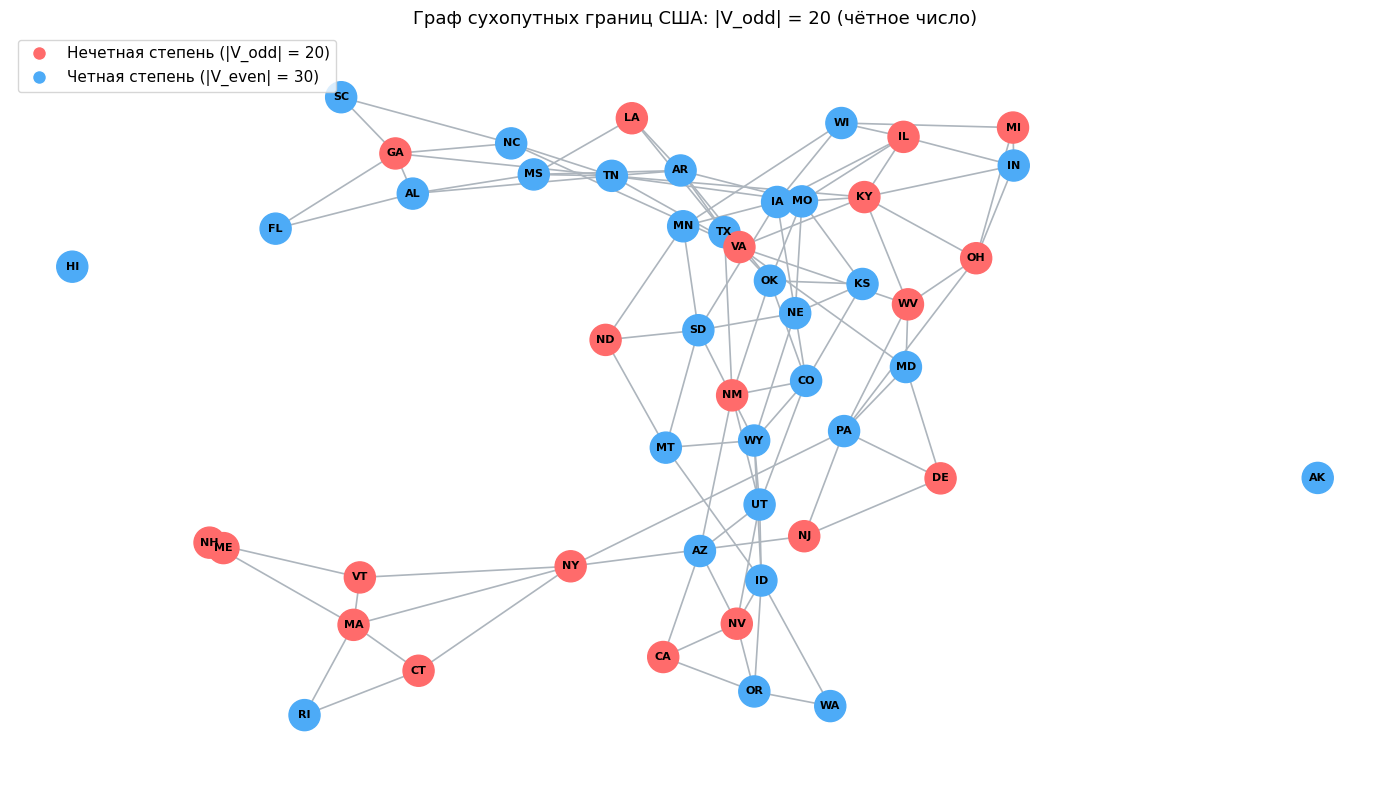

In [20]:


# Определения:
# 1. Неориентированный граф G = (V, E):
#    V — множество штатов (|V| = 50).
#    E — множество общих сухопутных границ между штатами ({u, v} in E, если u и v граничат).
# 2. Степень вершины deg(v) — количество инцидентных ей ребер, то есть количество соседей штата v.
# 3. Лемма о рукопожатиях (теорема Эйлера):
#    Сумма степеней всех вершин любого графа равна удвоенному числу его рёбер:
#    sum_{v in V} deg(v) = 2 * |E|.
#    Каждое ребро {u, v} соединяет ровно две вершины и дает вклад +1 в deg(u) и +1 в deg(v).

# Математическое доказательство:
# 1. Разобьем множество вершин V на два непересекающихся подмножества:
#    V_odd = {v in V | deg(v) = 1 (mod 2)} (штаты с нечетным числом соседей)
#    V_even = {v in V | deg(v) = 0 (mod 2)} (штаты с четным числом соседей)
# 2. Сумма степеней раскладывается на две суммы:
#    sum_{v in V_odd} deg(v) + sum_{v in V_even} deg(v) = 2 * |E|
# 3. Число 2 * |E| делится на 2 без остатка.
# 4. Каждое слагаемое в sum_{v in V_even} deg(v) четно, поэтому вся эта сумма четна.
# 5. Отсюда сумма степеней вершин из V_odd также обязана быть четной:
#    sum_{v in V_odd} deg(v) = 2 * |E| - sum_{v in V_even} deg(v) = 0 (mod 2).
# 6. Сумма нечетных чисел четна тогда и только тогда, когда количество слагаемых четно.
#    Так как каждое deg(v) для v in V_odd нечетно:
#    sum_{v in V_odd} deg(v) = sum_{v in V_odd} 1 = |V_odd| = 0 (mod 2).
# 7. Следовательно, мощность множества |V_odd| четна.
# Утверждение доказано для любого неориентированного графа, включая граф штатов США.

def solve_task_1_8():
    # Таблица смежности 50 штатов США по сухопутным границам
    us_adj = {
        'WA': ['ID', 'OR'], 'OR': ['WA', 'ID', 'NV', 'CA'], 'CA': ['OR', 'NV', 'AZ'],
        'ID': ['WA', 'OR', 'NV', 'UT', 'WY', 'MT'], 'NV': ['OR', 'ID', 'UT', 'AZ', 'CA'],
        'AZ': ['CA', 'NV', 'UT', 'NM'], 'UT': ['ID', 'NV', 'AZ', 'NM', 'CO', 'WY'],
        'MT': ['ID', 'WY', 'SD', 'ND'], 'WY': ['MT', 'ID', 'UT', 'CO', 'NE', 'SD'],
        'CO': ['WY', 'UT', 'NM', 'OK', 'KS', 'NE'], 'NM': ['AZ', 'UT', 'CO', 'OK', 'TX'],
        'ND': ['MT', 'SD', 'MN'], 'SD': ['ND', 'MT', 'WY', 'NE', 'IA', 'MN'],
        'NE': ['SD', 'WY', 'CO', 'KS', 'MO', 'IA'], 'KS': ['NE', 'CO', 'OK', 'MO'],
        'OK': ['KS', 'CO', 'NM', 'TX', 'AR', 'MO'], 'TX': ['NM', 'OK', 'AR', 'LA'],
        'MN': ['ND', 'SD', 'IA', 'WI'], 'IA': ['MN', 'SD', 'NE', 'MO', 'IL', 'WI'],
        'MO': ['IA', 'NE', 'KS', 'OK', 'AR', 'TN', 'KY', 'IL'],
        'AR': ['MO', 'OK', 'TX', 'LA', 'MS', 'TN'], 'LA': ['AR', 'TX', 'MS'],
        'WI': ['MN', 'IA', 'IL', 'MI'], 'IL': ['WI', 'IA', 'MO', 'KY', 'IN'],
        'MI': ['WI', 'IN', 'OH'], 'IN': ['MI', 'IL', 'KY', 'OH'],
        'KY': ['IL', 'MO', 'TN', 'VA', 'WV', 'OH', 'IN'],
        'TN': ['KY', 'MO', 'AR', 'MS', 'AL', 'GA', 'NC', 'VA'],
        'MS': ['TN', 'AR', 'LA', 'AL'], 'AL': ['TN', 'MS', 'FL', 'GA'],
        'GA': ['NC', 'TN', 'AL', 'FL', 'SC'], 'FL': ['AL', 'GA'],
        'OH': ['MI', 'IN', 'KY', 'WV', 'PA'], 'WV': ['OH', 'KY', 'VA', 'MD', 'PA'],
        'VA': ['WV', 'KY', 'TN', 'NC', 'MD'], 'NC': ['VA', 'TN', 'GA', 'SC'],
        'SC': ['NC', 'GA'], 'PA': ['OH', 'WV', 'MD', 'DE', 'NJ', 'NY'],
        'MD': ['PA', 'WV', 'VA', 'DE'], 'DE': ['MD', 'PA', 'NJ'],
        'NJ': ['PA', 'DE', 'NY'], 'NY': ['PA', 'NJ', 'CT', 'MA', 'VT'],
        'CT': ['NY', 'MA', 'RI'], 'RI': ['CT', 'MA'],
        'MA': ['NY', 'VT', 'NH', 'RI', 'CT'], 'VT': ['NY', 'MA', 'NH'],
        'NH': ['VT', 'MA', 'ME'], 'ME': ['NH'],
        'AK': [], 'HI': []
    }

    G = nx.Graph()
    for state, neighbors in us_adj.items():
        G.add_node(state)
        for nbr in neighbors:
            G.add_edge(state, nbr)

    degrees = dict(G.degree())
    v_odd = [v for v, d in degrees.items() if d % 2 != 0]
    v_even = [v for v, d in degrees.items() if d % 2 == 0]
    sum_deg = sum(degrees.values())
    num_edges = G.number_of_edges()

    print("--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.8 ---")
    print(f"Всего штатов (|V|): {len(degrees)}")
    print(f"Общее число границ (|E|): {num_edges}")
    print(f"Сумма степеней вершин: {sum_deg} (2 * |E| = {2 * num_edges})")
    print(f"Количество штатов с нечетным числом соседей (|V_odd|): {len(v_odd)}")
    print(f"Список нечетных штатов: {v_odd}")
    print(f"Количество штатов с четным числом соседей (|V_even|): {len(v_even)}")
    print(f"Проверка: {len(v_odd)} mod 2 = {len(v_odd) % 2} (число четно)")

    # Визуализация графа
    fig, ax = plt.subplots(figsize=(14, 8))
    pos = nx.spring_layout(G, seed=10, k=0.35)

    node_colors = ['#ff6b6b' if v in v_odd else '#4dabf7' for v in G.nodes()]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=500)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_weight='bold')
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#adb5bd', width=1.2)

    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label=f'Нечетная степень (|V_odd| = {len(v_odd)})', markerfacecolor='#ff6b6b', markersize=10),
        Line2D([0], [0], marker='o', color='w', label=f'Четная степень (|V_even| = {len(v_even)})', markerfacecolor='#4dabf7', markersize=10)
    ]
    ax.legend(handles=legend_elements, loc='upper left', fontsize=11)
    ax.set_title(f"Граф сухопутных границ США: |V_odd| = {len(v_odd)} (чётное число)", fontsize=13)
    ax.axis('off')

    plt.tight_layout()
    plt.show()

solve_task_1_8()

# 1.9
Резидент одной иностранной разведки сообщил в центр о готовящемся подписании ряда двусторонних соглашений между пятнадцатью бывшими республиками СССР. Согласно его донесению, каждая из них заключит договор ровно с тремя другими.

Заслуживает ли резидент доверия?

--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.9 ---
Число республик (|V|): 15
Степень каждой вершины (deg(v)): 3
Сумма степеней: 15 * 3 = 45
Требуемое число договоров (|E| = sum_deg / 2): 22.5
Является ли число договоров целым: False
Количество вершин нечетной степени: 15 (нечетное число)
Вывод: Сообщение резидента математически невозможно. Резидент доверия НЕ заслуживает.


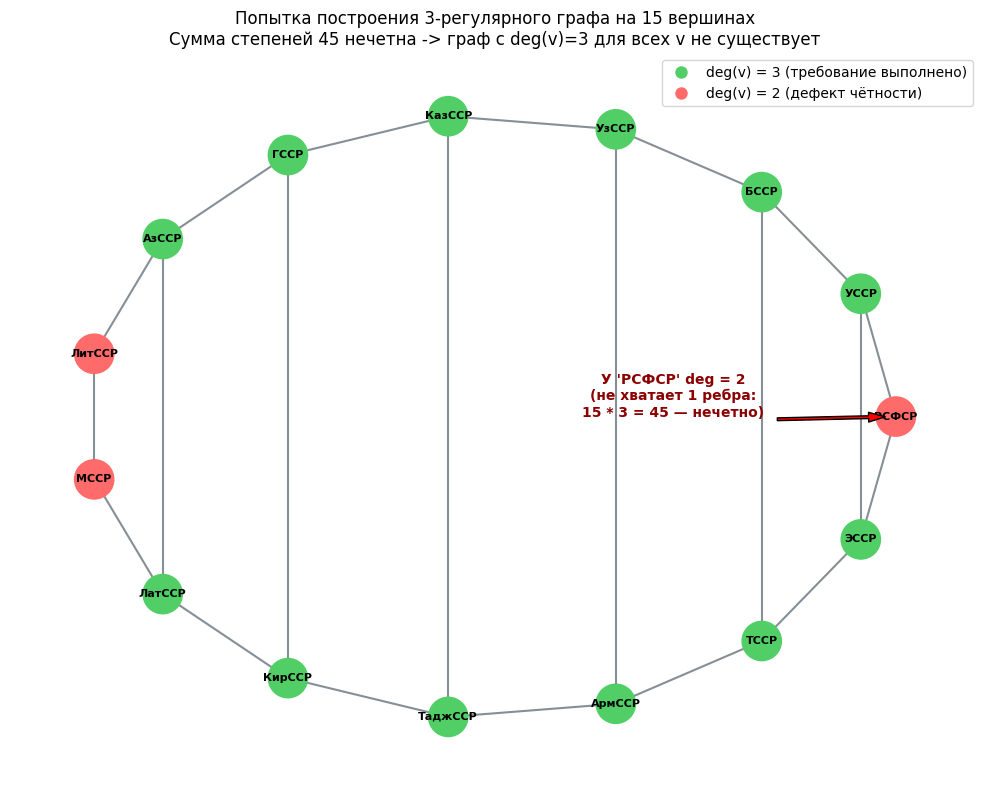

In [21]:
# Определения:
# 1. Модель задачи: неориентированный простой граф G = (V, E).
#    Множество вершин V — республики, |V| = 15.
#    Множество рёбер E — двусторонние соглашения.
# 2. Условие «каждая заключит договор ровно с тремя другими» означает,
#    что граф G является 3-регулярным: deg(v) = 3 для всех v in V.
# 3. Лемма о рукопожатиях:
#    sum_{v in V} deg(v) = 2 * |E|.

# Математическое доказательство невозможности:
# 1. Вычислим сумму степеней вершин при выполнении донесения:
#    sum_{v in V} deg(v) = |V| * 3 = 15 * 3 = 45.
# 2. Согласно лемме о рукопожатиях:
#    2 * |E| = 45  =>  |E| = 45 / 2 = 22.5.
# 3. Число соглашений (рёбер графа) |E| должно быть целым неотрицательным числом: |E| in Z_>=0.
#    Значение 22.5 не принадлежит Z.
# 4. Эквивалентно: по теореме о чётности числа нечётных вершин (следствие леммы о рукопожатиях),
#    число вершин с нечётной степенью в любом графе обязано быть чётным.
#    В донесении все 15 вершин имеют нечётную степень 3.
#    Число 15 нечётно: 15 = 1 (mod 2).
# 5. Граф с такими параметрами существовать не может.
# Ответ: Резидент не заслуживает доверия.

def solve_task_1_9():
    n = 15
    deg_val = 3
    sum_degrees = n * deg_val
    edges = sum_degrees / 2
    is_valid_integer = (sum_degrees % 2 == 0)

    print("--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.9 ---")
    print(f"Число республик (|V|): {n}")
    print(f"Степень каждой вершины (deg(v)): {deg_val}")
    print(f"Сумма степеней: {n} * {deg_val} = {sum_degrees}")
    print(f"Требуемое число договоров (|E| = sum_deg / 2): {edges}")
    print(f"Является ли число договоров целым: {is_valid_integer}")
    print(f"Количество вершин нечетной степени: {n} (нечетное число)")
    print("Вывод: Сообщение резидента математически невозможно. Резидент доверия НЕ заслуживает.")

    # Визуализация максимального приближения:
    # Строим граф, где 14 вершин имеют требуемую степень 3, а 1 вершина — степень 2.
    # Это демонстрирует неразрешимый дефект четности: одно «полуребро» не имеет пары.
    republics = [
        "РСФСР", "УССР", "БССР", "УзССР", "КазССР",
        "ГССР", "АзССР", "ЛитССР", "МССР", "ЛатССР",
        "КирССР", "ТаджССР", "АрмССР", "ТССР", "ЭССР"
    ]

    G = nx.Graph()
    G.add_nodes_from(republics)

    # Базовый цикл длины 15 (степень 2 для каждой вершины)
    for i in range(n):
        G.add_edge(republics[i], republics[(i + 1) % n])

    # Добавляем максимальное паросочетание хорд на 14 вершинах (7 хорд)
    # Вершина republics[0] остается со степенью 2
    for i in range(1, 8):
        G.add_edge(republics[i], republics[n - i])

    degrees = dict(G.degree())
    pos = nx.circular_layout(G)

    fig, ax = plt.subplots(figsize=(10, 8))
    node_colors = ['#ff6b6b' if degrees[r] == 2 else '#51cf66' for r in republics]

    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=800)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_weight='bold')
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#868e96', width=1.5)

    ax.annotate(
        f"У '{republics[0]}' deg = 2\n(не хватает 1 ребра:\n15 * 3 = 45 — нечетно)",
        xy=pos[republics[0]], xytext=(pos[republics[0]][0] * 0.45, pos[republics[0]][1] * 0.45),
        arrowprops=dict(facecolor='red', shrink=0.08, width=2, headwidth=7),
        fontsize=10, fontweight='bold', color='darkred', ha='center'
    )

    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='deg(v) = 3 (требование выполнено)', markerfacecolor='#51cf66', markersize=10),
        Line2D([0], [0], marker='o', color='w', label='deg(v) = 2 (дефект чётности)', markerfacecolor='#ff6b6b', markersize=10)
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=10)
    ax.set_title("Попытка построения 3-регулярного графа на 15 вершинах\nСумма степеней 45 нечетна -> граф с deg(v)=3 для всех v не существует", fontsize=12)
    ax.axis('off')

    plt.tight_layout()
    plt.show()

solve_task_1_9()

# 1.10
Какие-то две команды набрали в круговом волейбольном турнире одинаковое число очков.
Докажите, что найдутся такие команды А, В и С, что А выиграла у В, В выиграла у С, а С выиграла у А.

--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.10 ---
Число побед (очков) команд: {'T0': 2, 'T1': 2, 'T2': 2, 'T3': 2, 'T4': 2}
Выбраны команды с равными очками: T0 и T1 (по 2 очков)
Результат личной встречи: T0 победила T1
Победы T0 над остальными (W_T0): {'T2'}
Победы T1 над остальными (W_T1): {'T2', 'T3'}
Элемент разности Z in W_T1 \ W_T0: T3
Найден ориентированный 3-цикл: T0 -> T1 -> T3 -> T0
  T0 выиграла у T1: True
  T1 выиграла у T3: True
  T3 выиграла у T0: True


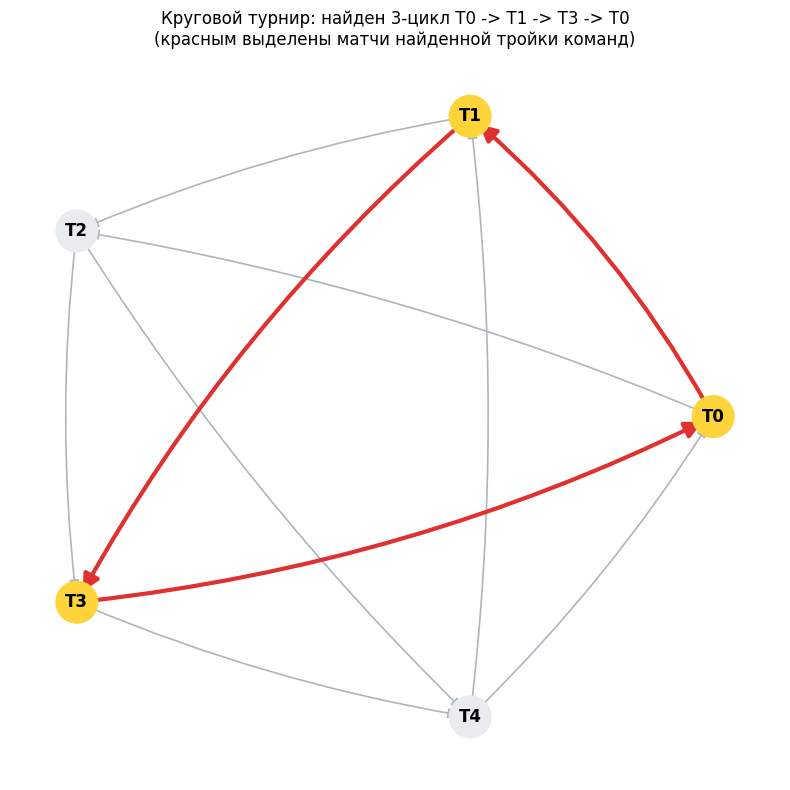

In [22]:
# Определения:
# 1. Круговой волейбольный турнир задается турниром T = (V, E) — полным ориентированным графом:
#    V — множество команд (|V| = n).
#    Для любой пары различных команд {u, v} существует ровно одна дуга: (u, v) in E или (v, u) in E.
# 2. В волейболе ничьих не бывает: каждый матч оканчивается победой одной команды.
# 3. Число очков (побед) команды v равно ее полустепени исхода: s(v) = deg^+(v) = |{u in V | (v, u) in E}|.
# 4. Требуемая конфигурация (A выиграла у B, B у C, C у A) — это ориентированный цикл длины 3:
#    (A, B) in E, (B, C) in E, (C, A) in E.

# Математическое доказательство:
# 1. Пусть две команды X и Y набрали одинаковое число очков: deg^+(X) = deg^+(Y) = k.
# 2. Между X и Y был сыгран матч. Без ограничения общности положим, что X победила Y:
#    дуга (X, Y) in E.
# 3. Рассмотрим множество остальных n - 2 команд: W = V \ {X, Y}.
# 4. Обозначим подмножества команд из W, у которых выиграли X и Y:
#    W_X = {w in W | (X, w) in E}
#    W_Y = {w in W | (Y, w) in E}
# 5. Вычислим мощности этих подмножеств:
#    - Команда X выиграла у Y, поэтому из остальных команд W она выиграла у k - 1 команды:
#      |W_X| = deg^+(X) - 1 = k - 1.
#    - Команда Y проиграла команде X, поэтому все свои k побед она одержала над командами из W:
#      |W_Y| = deg^+(Y) = k.
# 6. Сравнение мощностей:
#    |W_Y| = k > k - 1 = |W_X|.
#    Множество W_Y строго больше по мощности множества W_X, следовательно, W_Y не является подмножеством W_X.
#    Отсюда разность множеств не пуста: W_Y \ W_X != empty.
# 7. Выберем произвольную команду Z in W_Y \ W_X:
#    - Так как Z in W_Y, то Y выиграла у Z: (Y, Z) in E.
#    - Так как Z not in W_X и Z != X, команда X не выиграла у Z.
#      Так как турнир полный и без ничьих, это означает, что Z выиграла у X: (Z, X) in E.
# 8. Мы получили тройку матчей:
#    (X, Y) in E, (Y, Z) in E, (Z, X) in E.
#    Полагая A = X, B = Y, C = Z, получаем цикл: A выиграла у B, B выиграла у C, C выиграла у A.
# Утверждение полностью доказано.

def solve_task_1_10():
    teams = ['T0', 'T1', 'T2', 'T3', 'T4']
    n = len(teams)

    # Турнир с равным числом побед (регулярный турнир, у каждого по 2 победы)
    # Матрица смежности: adj[i][j] = 1 означает i выиграл у j
    adj_matrix = [
        [0, 1, 1, 0, 0],
        [0, 0, 1, 1, 0],
        [0, 0, 0, 1, 1],
        [1, 0, 0, 0, 1],
        [1, 1, 0, 0, 0]
    ]

    T = nx.DiGraph()
    T.add_nodes_from(teams)
    for i in range(n):
        for j in range(n):
            if adj_matrix[i][j] == 1:
                T.add_edge(teams[i], teams[j])

    scores = {v: T.out_degree(v) for v in teams}

    # Алгоритмический поиск цикла по формуле доказательства
    found_cycle = None
    for i in range(n):
        for j in range(i + 1, n):
            if scores[teams[i]] == scores[teams[j]]:
                u, v = teams[i], teams[j]
                X, Y = (u, v) if T.has_edge(u, v) else (v, u)
                W_X = {w for w in teams if w not in (X, Y) and T.has_edge(X, w)}
                W_Y = {w for w in teams if w not in (X, Y) and T.has_edge(Y, w)}
                diff = W_Y - W_X
                if diff:
                    Z = sorted(list(diff))[0]
                    found_cycle = (X, Y, Z)
                    break
        if found_cycle:
            break

    A, B, C = found_cycle

    print("--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.10 ---")
    print(f"Число побед (очков) команд: {scores}")
    print(f"Выбраны команды с равными очками: {A} и {B} (по {scores[A]} очков)")
    print(f"Результат личной встречи: {A} победила {B}")
    print(f"Победы {A} над остальными (W_{A}): { {w for w in teams if w not in (A, B) and T.has_edge(A, w)} }")
    print(f"Победы {B} над остальными (W_{B}): { {w for w in teams if w not in (A, B) and T.has_edge(B, w)} }")
    print(f"Элемент разности Z in W_{B} \\ W_{A}: {C}")
    print(f"Найден ориентированный 3-цикл: {A} -> {B} -> {C} -> {A}")
    print(f"  {A} выиграла у {B}: {T.has_edge(A, B)}")
    print(f"  {B} выиграла у {C}: {T.has_edge(B, C)}")
    print(f"  {C} выиграла у {A}: {T.has_edge(C, A)}")

    # Визуализация графа турнира с подсветкой цикла
    fig, ax = plt.subplots(figsize=(8, 8))
    pos = nx.circular_layout(T)

    cycle_edges = [(A, B), (B, C), (C, A)]
    other_edges = [e for e in T.edges() if e not in cycle_edges]

    node_colors = ['#ffd43b' if node in (A, B, C) else '#e9ecef' for node in T.nodes()]
    nx.draw_networkx_nodes(T, pos, ax=ax, node_color=node_colors, node_size=900)
    nx.draw_networkx_labels(T, pos, ax=ax, font_size=12, font_weight='bold')

    nx.draw_networkx_edges(
        T, pos, edgelist=other_edges, ax=ax, edge_color='#adb5bd',
        width=1.2, arrows=True, arrowsize=15, connectionstyle='arc3,rad=0.06'
    )
    nx.draw_networkx_edges(
        T, pos, edgelist=cycle_edges, ax=ax, edge_color='#e03131',
        width=3.0, arrows=True, arrowsize=25, connectionstyle='arc3,rad=0.09'
    )

    ax.set_title(f"Круговой турнир: найден 3-цикл {A} -> {B} -> {C} -> {A}\n(красным выделены матчи найденной тройки команд)", fontsize=12)
    ax.axis('off')

    plt.tight_layout()
    plt.show()

solve_task_1_10()

# 1.11
Докажите, что не существует графа с пятью вершинами, степени которых равны 4, 4, 4, 4, 2.

--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.11 ---
Исходная последовательность степеней: [4, 4, 4, 4, 2]
Шаг 0: [4, 4, 4, 4, 2]
Шаг 1 (удалили вершину со степенью 4): [3, 3, 3, 1]
Шаг 2 (удалили вершину со степенью 3): [2, 2, 0]
Шаг 3 (удалили вершину со степенью 2): [1, -1]
Последовательность графическая: False
Вывод: Графа с пятью вершинами со степенями 4, 4, 4, 4, 2 не существует.


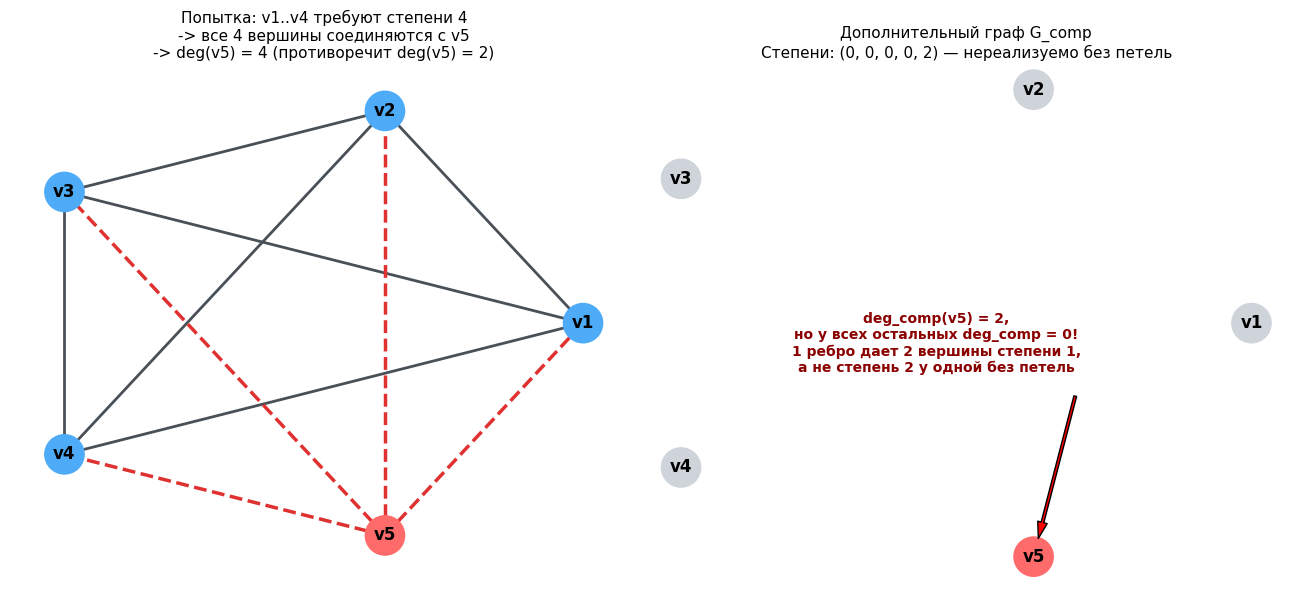

In [23]:
# Определения:
# 1. Простой граф G = (V, E) — граф без петель и без кратных рёбер.
# 2. В простом графе с n = |V| вершинами максимальная степень любой вершины равна n - 1.
#    Для n = 5: deg(v) <= 5 - 1 = 4 для любого v in V.
# 3. Вершина степени n - 1 соединена ребром со всеми остальными n - 1 вершинами графа.
# 4. Дополнительный граф G_comp = (V, E_comp) — граф на том же множестве вершин V,
#    в котором ребро {u, v} существует тогда и только тогда, когда {u, v} не принадлежит E.
#    Степень вершины в дополнительном графе: deg_comp(v) = (n - 1) - deg(v).

# Математические доказательства несуществования:

# Метод 1: Прямое комбинаторное доказательство (по инцидентности)
# 1. Пусть V = {v1, v2, v3, v4, v5}.
#    По условию deg(v1) = deg(v2) = deg(v3) = deg(v4) = 4, а deg(v5) = 2.
# 2. Так как deg(v1) = 4, вершина v1 соединена со всеми остальными вершинами графа.
#    В частности, ребро {v1, v5} in E.
# 3. Так как deg(v2) = 4, ребро {v2, v5} in E.
# 4. Так как deg(v3) = 4, ребро {v3, v5} in E.
# 5. Так как deg(v4) = 4, ребро {v4, v5} in E.
# 6. Вершина v5 соединена с каждой из вершин {v1, v2, v3, v4}.
# 7. Следовательно, степень вершины v5 обязана удовлетворять неравенству:
#    deg(v5) >= 4.
# 8. Однако по условию задачи deg(v5) = 2.
#    Получили противоречие: 2 >= 4 — ложно.
# Следовательно, такого графа не существует.

# Метод 2: Через дополнительный граф
# 1. Для n = 5 степени в дополнительном графе G_comp равны:
#    deg_comp(v1) = 4 - 4 = 0
#    deg_comp(v2) = 4 - 4 = 0
#    deg_comp(v3) = 4 - 4 = 0
#    deg_comp(v4) = 4 - 4 = 0
#    deg_comp(v5) = 4 - 2 = 2
# 2. Сумма степеней в G_comp равна: 0 + 0 + 0 + 0 + 2 = 2.
# 3. Число ребер в G_comp: |E_comp| = 2 / 2 = 1.
# 4. Одно ребро в простом графе соединяет две различные вершины,
#    поэтому граф с 1 ребром имеет две вершины степени 1 и три изолированные вершины: (1, 1, 0, 0, 0).
#    Граф со степенями (2, 0, 0, 0, 0) требует петли на вершине v5, что запрещено определением простого графа.

# Метод 3: Критерий Гавела — Хакими
# Исходная последовательность: S_0 = (4, 4, 4, 4, 2)
# Шаг 1: Удаляем 4, вычитаем 1 из следующих 4 элементов:
#        S_1 = (4-1, 4-1, 4-1, 2-1) = (3, 3, 3, 1)
# Шаг 2: Удаляем 3, вычитаем 1 из следующих 3 элементов:
#        S_2 = (3-1, 3-1, 1-1) = (2, 2, 0)
# Шаг 3: Удаляем 2, вычитаем 1 из следующих 2 элементов:
#        S_3 = (2-1, 0-1) = (1, -1)
# Появился отрицательный элемент (-1). Последовательность не является графической.

def solve_task_1_11():
    seq = [4, 4, 4, 4, 2]
    print("--- РЕЗУЛЬТАТЫ ЗАДАНИЯ 1.11 ---")
    print(f"Исходная последовательность степеней: {seq}")

    # Пошаговый алгоритм Гавела-Хакими
    current = sorted(seq, reverse=True)
    step = 0
    print(f"Шаг {step}: {current}")
    is_graphical = True
    while current:
        d = current.pop(0)
        if d == 0:
            continue
        if d > len(current):
            is_graphical = False
            break
        for i in range(d):
            current[i] -= 1
            if current[i] < 0:
                is_graphical = False
        current.sort(reverse=True)
        step += 1
        print(f"Шаг {step} (удалили вершину со степенью {d}): {current}")
        if not is_graphical:
            break

    print(f"Последовательность графическая: {is_graphical}")
    print("Вывод: Графа с пятью вершинами со степенями 4, 4, 4, 4, 2 не существует.")

    # Визуализация противоречия
    nodes = ['v1', 'v2', 'v3', 'v4', 'v5']
    G_complete = nx.complete_graph(nodes)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
    pos = nx.circular_layout(nodes)

    # Левый график: вершины v1..v4 со степенью 4 принудительно дают deg(v5)=4
    edges_v5 = [('v5', 'v1'), ('v5', 'v2'), ('v5', 'v3'), ('v5', 'v4')]
    other_edges = [e for e in G_complete.edges() if 'v5' not in e]

    nx.draw_networkx_nodes(G_complete, pos, ax=ax1, node_color=['#4dabf7' if n != 'v5' else '#ff6b6b' for n in nodes], node_size=800)
    nx.draw_networkx_labels(G_complete, pos, ax=ax1, font_size=12, font_weight='bold')
    nx.draw_networkx_edges(G_complete, pos, edgelist=other_edges, ax=ax1, edge_color='#495057', width=2)
    nx.draw_networkx_edges(G_complete, pos, edgelist=edges_v5, ax=ax1, edge_color='#e03131', width=2.5, style='dashed')
    ax1.set_title("Попытка: v1..v4 требуют степени 4\n-> все 4 вершины соединяются с v5\n-> deg(v5) = 4 (противоречит deg(v5) = 2)", fontsize=11)
    ax1.axis('off')

    # Правый график: дополнительный граф G_comp со степенями (0, 0, 0, 0, 2)
    G_comp = nx.Graph()
    G_comp.add_nodes_from(nodes)
    nx.draw_networkx_nodes(G_comp, pos, ax=ax2, node_color=['#ced4da' if n != 'v5' else '#ff6b6b' for n in nodes], node_size=800)
    nx.draw_networkx_labels(G_comp, pos, ax=ax2, font_size=12, font_weight='bold')
    ax2.annotate(
        "deg_comp(v5) = 2,\nно у всех остальных deg_comp = 0!\n1 ребро дает 2 вершины степени 1,\nа не степень 2 у одной без петель",
        xy=pos['v5'], xytext=(0, -0.2),
        arrowprops=dict(facecolor='red', shrink=0.1, width=2, headwidth=7),
        fontsize=10, fontweight='bold', color='darkred', ha='center'
    )
    ax2.set_title("Дополнительный граф G_comp\nСтепени: (0, 0, 0, 0, 2) — нереализуемо без петель", fontsize=11)
    ax2.axis('off')

    plt.tight_layout()
    plt.show()

solve_task_1_11()

# 1.12

# 1.13

# 1.14

# 1.15